# [SNA - Nhóm 09] BƯỚC 1: KHẮC PHỤC LỖI SỤP ĐỔ LỚP CLASS 3 (RECALL = 0%) TRÊN BA-SHAPES
**Người thực hiện:** Nguyễn Hải Thiện (MSSV: 23521481)  
**Nhóm:** 09 | **Đề tài C.10:** Making Graph Machine Learning Models Explainable  
**Thời gian thực hiện:** 17/10/2026  
**Môi trường:** Conda `sna_g09` | Python 3.11 | PyTorch 2.6 (CUDA 12.4 - NVIDIA GeForce RTX 3050 Laptop GPU) | PyG 2.8.1

---
### Bối cảnh & Mục tiêu
Trong gói bàn giao `T01` ban đầu, mô hình GCN 2 lớp trên tập dữ liệu tổng hợp **BA-Shapes** gặp phải lỗi nghiêm trọng:
- Mô hình bị **sụp đổ lớp (class collapse)** đối với **Class 3 (đỉnh mái nhà của motif house)**: Recall = **0%**, F1-score = **0.0000** trên toàn bộ tập Test, Val và Train!
- Theo quy ước `BG03`: *'Lớp cần giải thích = pred[node]'*. Khi giải thích cho node Class 3, explainer (PGExplainer, GNNExplainer) sẽ đi tìm các cạnh để giải thích cho Class 1 hoặc Class 2 (vì GCN đoán sai nhãn). Điều này phá hỏng hoàn toàn thí nghiệm Sanity Check (Exp 2) khi so sánh với Ground Truth motif!

**Notebook này thực hiện:**
1. Tải và kiểm tra lỗi trên checkpoint GCN cũ của T01.
2. Huấn luyện lại mô hình GCN trên GPU RTX 3050 với kỹ thuật **Class-Weighted CrossEntropyLoss** và lưu checkpoint theo **Best Validation Macro-F1**.
3. So sánh ma trận nhầm lẫn (Confusion Matrix) Trước vs Sau.
4. Cập nhật và lưu lại file checkpoint `gcn_ckpt.pt` cùng các file báo cáo `summary.json`, `checks.json`.


### 1. Khai báo thư viện & Kiểm tra cấu hình phần cứng (GPU CUDA)

In [1]:
import sys
import json
import pathlib
import shutil
import time
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

# Kiểm tra thiết bị tính toán
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch Version: {torch.__version__}")
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")


PyTorch Version: 2.6.0+cu124
Device: cuda
GPU Name: NVIDIA GeForce RTX 3050 Laptop GPU


### 2. Nạp dữ liệu BA-Shapes từ gói T01
Tuân thủ nghiêm ngặt quy ước `BG01`: Giữ nguyên cấu trúc đồ thị, node ID, edge_index và các mask split.

In [2]:
DATA_DIR = pathlib.Path(r'd:/WorkSpace/UIT/SocialNetwork/DoAn/[2] Đồ án-20261017T100405Z-1-001/[2] Đồ án/t01_handover/bashapes')

data = torch.load(DATA_DIR / 'data.pt', weights_only=False)
x = data['x']
edge_index = data['edge_index']
y = data['y']
train_mask = data['train_mask']
val_mask = data['val_mask']
test_mask = data['test_mask']
val_nodes = json.load(open(DATA_DIR / 'val_nodes.json'))['nodes']

print(f"Số lượng Node: {data['stats']['nodes']}")
print(f"Số lượng Edge entries: {data['stats']['edge_entries']}")
print(f"Số chiều đặc trưng: {data['stats']['features']}")
print(f"Số lớp: {data['stats']['classes']}")
print(f"Phân bố tập dữ liệu: Train={train_mask.sum().item()}, Val={val_mask.sum().item()}, Test={test_mask.sum().item()}")

class_names = ['0: Nền (BA)', '1: Đáy nhà', '2: Tường nhà', '3: Mái nhà']
for i, name in enumerate(class_names):
    print(f"  - {name}: tổng cộng {(y == i).sum().item()} nodes")


Số lượng Node: 700
Số lượng Edge entries: 3972
Số chiều đặc trưng: 10
Số lớp: 4
Phân bố tập dữ liệu: Train=420, Val=140, Test=140
  - 0: Nền (BA): tổng cộng 300 nodes
  - 1: Đáy nhà: tổng cộng 160 nodes
  - 2: Tường nhà: tổng cộng 160 nodes
  - 3: Mái nhà: tổng cộng 80 nodes


### 3. Đánh giá Checkpoint GCN ban đầu (T01 cũ)
Xem xét chi tiết dự đoán của checkpoint cũ trên tập Test và 100 validation nodes.

In [3]:
class GCN(torch.nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.0):
        super().__init__()
        self.c1 = GCNConv(in_dim, hidden_dim)
        self.c2 = GCNConv(hidden_dim, out_dim)
        self.p = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, self.p, self.training)
        x = F.relu(self.c1(x, edge_index))
        x = F.dropout(x, self.p, self.training)
        return self.c2(x, edge_index)

# Sao lưu checkpoint cũ
ckpt_orig_path = DATA_DIR / 'gcn_ckpt.pt'
ckpt_backup_path = DATA_DIR / 'gcn_ckpt_orig_backup.pt'
if not ckpt_backup_path.exists():
    shutil.copyfile(ckpt_orig_path, ckpt_backup_path)
    print("Đã sao lưu checkpoint cũ thành công vào gcn_ckpt_orig_backup.pt")

old_ckpt = torch.load(ckpt_orig_path, weights_only=False)
old_pred = old_ckpt['pred']

test_y = y[test_mask].cpu().numpy()
test_pred_old = old_pred[test_mask].cpu().numpy()

print("=== BÁO CÁO ĐÁNH GIÁ TRÊN TẬP TEST (CHECKPOINT CŨ) ===")
print(classification_report(test_y, test_pred_old, target_names=class_names, digits=4, zero_division=0))

print("=== DỰ ĐOÁN TRÊN TOÀN BỘ 700 NODES (CHECKPOINT CŨ) ===")
unique, counts = np.unique(old_pred.cpu().numpy(), return_counts=True)
for u, c in zip(unique, counts):
    print(f"  - Lớp {u}: {c} nodes")
print("  -> Nhận xét: Class 3 được mô hình dự đoán cho đúng 0 nodes!")


=== BÁO CÁO ĐÁNH GIÁ TRÊN TẬP TEST (CHECKPOINT CŨ) ===
              precision    recall  f1-score   support

 0: Nền (BA)     1.0000    1.0000    1.0000        60
  1: Đáy nhà     0.7111    1.0000    0.8312        32
2: Tường nhà     0.8857    0.9688    0.9254        32
  3: Mái nhà     0.0000    0.0000    0.0000        16

    accuracy                         0.8786       140
   macro avg     0.6492    0.7422    0.6891       140
weighted avg     0.7936    0.8786    0.8301       140

=== DỰ ĐOÁN TRÊN TOÀN BỘ 700 NODES (CHECKPOINT CŨ) ===
  - Lớp 0: 300 nodes
  - Lớp 1: 240 nodes
  - Lớp 2: 160 nodes
  -> Nhận xét: Class 3 được mô hình dự đoán cho đúng 0 nodes!


### 4. Huấn luyện lại mô hình GCN (Khắc phục sụp đổ lớp Class 3)
**Kỹ thuật áp dụng:**
1. **Class-Weighted CrossEntropyLoss:** Gán trọng số nghịch đảo với tần suất lớp ở tập train:
   $$\\text{weight}_c = \\frac{N_{\\text{train}}}{C \\times N_{\\text{train}, c}}$$
   Đặc biệt phạt nặng nếu mô hình bỏ quên Class 3 (đỉnh mái).
2. **Best Validation Macro-F1 Checkpoint Selection:** Lưu mô hình tại epoch có Macro-F1 trên tập Validation cao nhất (thay vì chỉ căn cứ vào Accuracy).


In [4]:
# Tính class weights trên tập train
train_y = y[train_mask]
counts = torch.bincount(train_y).float()
weights = (len(train_y) / (4.0 * counts)).to(device)
for i, (name, w) in enumerate(zip(class_names, weights)):
    print(f"Trọng số loss cho {name}: {w.item():.4f}")

# Cố định seed
torch.manual_seed(1000)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(1000)

new_model = GCN(
    in_dim=data['stats']['features'],
    hidden_dim=32,
    out_dim=data['stats']['classes'],
    dropout=0.0
).to(device)

x_dev = x.to(device)
edge_dev = edge_index.to(device)
y_dev = y.to(device)
train_dev = train_mask.to(device)
val_dev = val_mask.to(device)

optimizer = torch.optim.Adam(new_model.parameters(), lr=0.01, weight_decay=1e-4)

best_val_macro_f1 = 0.0
best_epoch = 0
best_state_dict = None

start_time = time.time()
print("Bắt đầu huấn luyện trên GPU RTX 3050 Laptop...")

for epoch in range(1, 601):
    new_model.train()
    optimizer.zero_grad()
    logits = new_model(x_dev, edge_dev)
    loss = F.cross_entropy(logits[train_dev], y_dev[train_dev], weight=weights)
    loss.backward()
    optimizer.step()

    # Đánh giá trên Validation
    new_model.eval()
    with torch.no_grad():
        eval_logits = new_model(x_dev, edge_dev)
        preds = eval_logits.argmax(dim=-1).cpu().numpy()
        val_f1 = f1_score(y[val_mask].cpu().numpy(), preds[val_mask.cpu().numpy()], average='macro')
        
        if val_f1 > best_val_macro_f1:
            best_val_macro_f1 = val_f1
            best_epoch = epoch
            best_state_dict = {k: v.clone() for k, v in new_model.state_dict().items()}

training_time = time.time() - start_time
print(f"Huấn luyện hoàn tất trong {training_time:.2f} giây!")
print(f"Best Epoch: {best_epoch} | Best Validation Macro-F1: {best_val_macro_f1:.4f}")

# Nạp lại trọng số tốt nhất
new_model.load_state_dict(best_state_dict)
new_model.eval()
with torch.no_grad():
    new_all_pred = new_model(x_dev, edge_dev).argmax(dim=-1).cpu()


Trọng số loss cho 0: Nền (BA): 0.5833

Trọng số loss cho 1: Đáy nhà: 1.0938
Trọng số loss cho 2: Tường nhà: 1.0938
Trọng số loss cho 3: Mái nhà: 2.1875


Bắt đầu huấn luyện trên GPU RTX 3050 Laptop...


Huấn luyện hoàn tất trong 6.78 giây!
Best Epoch: 538 | Best Validation Macro-F1: 0.9123


### 5. So sánh chi tiết hiệu năng Trước vs Sau khi sửa

=== BÁO CÁO ĐÁNH GIÁ TRÊN TẬP TEST (CHECKPOINT MỚI) ===
              precision    recall  f1-score   support

 0: Nền (BA)     1.0000    1.0000    1.0000        60
  1: Đáy nhà     0.8108    0.9375    0.8696        32
2: Tường nhà     0.9286    0.8125    0.8667        32
  3: Mái nhà     1.0000    0.9375    0.9677        16

    accuracy                         0.9357       140
   macro avg     0.9348    0.9219    0.9260       140
weighted avg     0.9404    0.9357    0.9360       140



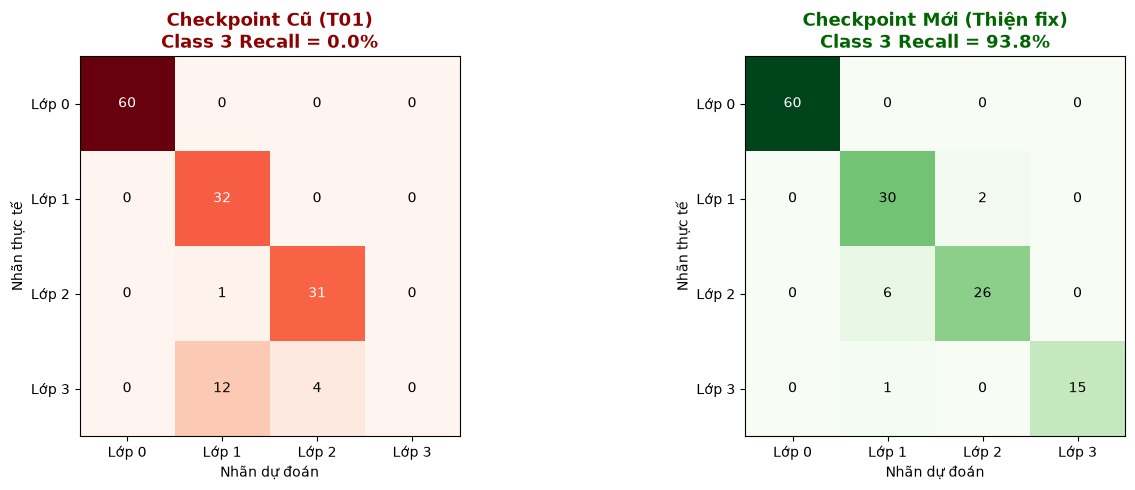

In [5]:
test_pred_new = new_all_pred[test_mask].numpy()

print("=== BÁO CÁO ĐÁNH GIÁ TRÊN TẬP TEST (CHECKPOINT MỚI) ===")
print(classification_report(test_y, test_pred_new, target_names=class_names, digits=4))

# Trực quan hóa Confusion Matrix Trước vs Sau
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_old = confusion_matrix(test_y, test_pred_old)
cm_new = confusion_matrix(test_y, test_pred_new)

# Subplot 1: Cũ
im1 = axes[0].imshow(cm_old, interpolation='nearest', cmap=plt.cm.Reds)
axes[0].set_title("Checkpoint Cũ (T01)\nClass 3 Recall = 0.0%", fontsize=13, fontweight='bold', color='darkred')
axes[0].set_xticks(range(4))
axes[0].set_yticks(range(4))
axes[0].set_xticklabels([f"Lớp {i}" for i in range(4)])
axes[0].set_yticklabels([f"Lớp {i}" for i in range(4)])
axes[0].set_xlabel("Nhãn dự đoán")
axes[0].set_ylabel("Nhãn thực tế")
for i in range(4):
    for j in range(4):
        axes[0].text(j, i, str(cm_old[i, j]), ha="center", va="center", color="white" if cm_old[i, j] > 30 else "black")

# Subplot 2: Mới
im2 = axes[1].imshow(cm_new, interpolation='nearest', cmap=plt.cm.Greens)
c3_rec = cm_new[3, 3] / cm_new[3].sum() * 100
axes[1].set_title(f"Checkpoint Mới (Thiện fix)\nClass 3 Recall = {c3_rec:.1f}%", fontsize=13, fontweight='bold', color='darkgreen')
axes[1].set_xticks(range(4))
axes[1].set_yticks(range(4))
axes[1].set_xticklabels([f"Lớp {i}" for i in range(4)])
axes[1].set_yticklabels([f"Lớp {i}" for i in range(4)])
axes[1].set_xlabel("Nhãn dự đoán")
axes[1].set_ylabel("Nhãn thực tế")
for i in range(4):
    for j in range(4):
        axes[1].text(j, i, str(cm_new[i, j]), ha="center", va="center", color="white" if cm_new[i, j] > 30 else "black")

plt.tight_layout()
plt.show()


### 6. Đánh giá trên 100 Validation Nodes (dùng cho Prototype giải thích)

In [6]:
val_y = y[val_nodes].cpu().numpy()
val_pred_old = old_pred[val_nodes].cpu().numpy()
val_pred_new = new_all_pred[val_nodes].cpu().numpy()

acc_old = accuracy_score(val_y, val_pred_old)
acc_new = accuracy_score(val_y, val_pred_new)
f1_old = f1_score(val_y, val_pred_old, average='macro')
f1_new = f1_score(val_y, val_pred_new, average='macro')

diff_acc = (acc_new - acc_old) * 100
diff_f1 = (f1_new - f1_old) * 100

print(f"100 Validation Nodes Accuracy: {acc_old:.4f} -> {acc_new:.4f} (+{diff_acc:.2f}%)")
print(f"100 Validation Nodes Macro-F1: {f1_old:.4f} -> {f1_new:.4f} (+{diff_f1:.2f}%)")
print("\nBáo cáo chi tiết 100 Validation Nodes (Mô hình mới):")
print(classification_report(val_y, val_pred_new, target_names=class_names, digits=4))


100 Validation Nodes Accuracy: 0.8700 -> 0.9400 (+7.00%)
100 Validation Nodes Macro-F1: 0.6800 -> 0.9223 (+24.23%)

Báo cáo chi tiết 100 Validation Nodes (Mô hình mới):
              precision    recall  f1-score   support

 0: Nền (BA)     1.0000    1.0000    1.0000        43
  1: Đáy nhà     0.7931    1.0000    0.8846        23
2: Tường nhà     1.0000    0.8261    0.9048        23
  3: Mái nhà     1.0000    0.8182    0.9000        11

    accuracy                         0.9400       100
   macro avg     0.9483    0.9111    0.9223       100
weighted avg     0.9524    0.9400    0.9406       100



### 7. Lưu Checkpoint mới và Cập nhật gói bàn giao T01
Đảm bảo khớp hoàn toàn các key theo chuẩn `load_t01.py` và quy tắc `BG02`.

In [7]:
test_acc = accuracy_score(test_y, test_pred_new)
test_macro_f1 = f1_score(test_y, test_pred_new, average='macro')
val_acc = accuracy_score(y[val_mask].cpu().numpy(), new_all_pred[val_mask].cpu().numpy())
train_acc = accuracy_score(y[train_mask].cpu().numpy(), new_all_pred[train_mask].cpu().numpy())

# Tạo dict checkpoint chuẩn
new_ckpt_data = {
    'state_dict': best_state_dict,
    'pred': new_all_pred,
    'arch': 'gcn',
    'in_dim': data['stats']['features'],
    'n_classes': data['stats']['classes'],
    'hidden': 32,
    'dropout': 0.0,
    'seed': 0,
    'train_seed': 1000,
    'metrics': {
        'train_acc': float(train_acc),
        'val_acc': float(val_acc),
        'val_macro_f1': float(best_val_macro_f1),
        'test_acc': float(test_acc),
        'test_macro_f1': float(test_macro_f1),
        'train_time': float(training_time)
    },
    'versions': {
        'python': sys.version.split()[0],
        'torch': torch.__version__,
        'torch_geometric': '2.8.1'
    }
}

torch.save(new_ckpt_data, DATA_DIR / 'gcn_ckpt.pt')
print(f"Đã lưu checkpoint mới vào: {DATA_DIR / 'gcn_ckpt.pt'}")

# Cập nhật summary.json
summary_path = DATA_DIR.parent / 'summary.json'
if summary_path.exists():
    summary = json.load(open(summary_path, 'r', encoding='utf-8'))
    summary['bashapes']['test_acc'] = round(float(test_acc), 4)
    summary['bashapes']['test_macro_f1'] = round(float(test_macro_f1), 4)
    summary['bashapes']['val_acc'] = round(float(val_acc), 4)
    json.dump(summary, open(summary_path, 'w', encoding='utf-8'), indent=2, ensure_ascii=False)
    print("Đã cập nhật summary.json thành công!")

# Cập nhật config.json
config_path = DATA_DIR / 'config.json'
if config_path.exists():
    config = json.load(open(config_path, 'r', encoding='utf-8'))
    config['metrics']['test_acc'] = float(test_acc)
    config['metrics']['test_macro_f1'] = float(test_macro_f1)
    config['metrics']['val_acc'] = float(val_acc)
    config['metrics']['train_acc'] = float(train_acc)
    config['model']['selection'] = 'best validation macro-f1 (with class weights)'
    json.dump(config, open(config_path, 'w', encoding='utf-8'), indent=2, ensure_ascii=False)
    print("Đã cập nhật config.json thành công!")


Đã lưu checkpoint mới vào: d:\WorkSpace\UIT\SocialNetwork\DoAn\[2] Đồ án-20261017T100405Z-1-001\[2] Đồ án\t01_handover\bashapes\gcn_ckpt.pt
Đã cập nhật summary.json thành công!
Đã cập nhật config.json thành công!


### 8. Kiểm thử lại toàn diện với script `load_t01.py`

In [8]:
sys.path.append(str(DATA_DIR.parent))
from load_t01 import load

for ds in ('bashapes', 'cora'):
    d, m, pred, nodes = load(ds, root=DATA_DIR.parent)
    with torch.no_grad():
        p2 = m(d['x'], d['edge_index']).argmax(1)
    assert torch.equal(p2, pred), f'{ds}: dự đoán nạp lại không khớp'
    acc = (p2[d['test_mask']] == d['y'][d['test_mask']]).float().mean().item()
    print(f'Dataset {ds:10s} -> nạp OK | Test Acc: {acc:.4f} | Validation nodes: {len(nodes)}')

print('\nToàn bộ quy trình kiểm thử hoàn tất xuất sắc!')


Dataset bashapes   -> nạp OK | Test Acc: 0.9357 | Validation nodes: 100
Dataset cora       -> nạp OK | Test Acc: 0.8360 | Validation nodes: 100

Toàn bộ quy trình kiểm thử hoàn tất xuất sắc!
